Original Dataset:
    Salary
0    25000
1    28000
2    30000
3    32000
4    35000
5    38000
6    40000
7    42000
8    45000
9    48000
10   50000
11   52000
12   55000
13   58000
14   60000
15   65000
16   70000
17   75000
18   80000
19  250000


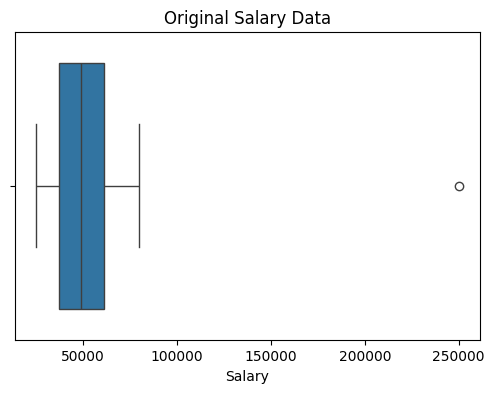


IQR Method
Q1: 37250.0
Q3: 61250.0
IQR: 24000.0
Lower Bound: 1250.0
Upper Bound: 97250.0

Outliers using IQR:
    Salary
19  250000

Dataset after IQR Capping:
    Salary  Salary_Capped
0    25000          25000
1    28000          28000
2    30000          30000
3    32000          32000
4    35000          35000
5    38000          38000
6    40000          40000
7    42000          42000
8    45000          45000
9    48000          48000
10   50000          50000
11   52000          52000
12   55000          55000
13   58000          58000
14   60000          60000
15   65000          65000
16   70000          70000
17   75000          75000
18   80000          80000
19  250000          97250

Dataset after removing IQR outliers:
    Salary
0    25000
1    28000
2    30000
3    32000
4    35000
5    38000
6    40000
7    42000
8    45000
9    48000
10   50000
11   52000
12   55000
13   58000
14   60000
15   65000
16   70000
17   75000
18   80000

Z-Score values:
    Salary   Z_Sco

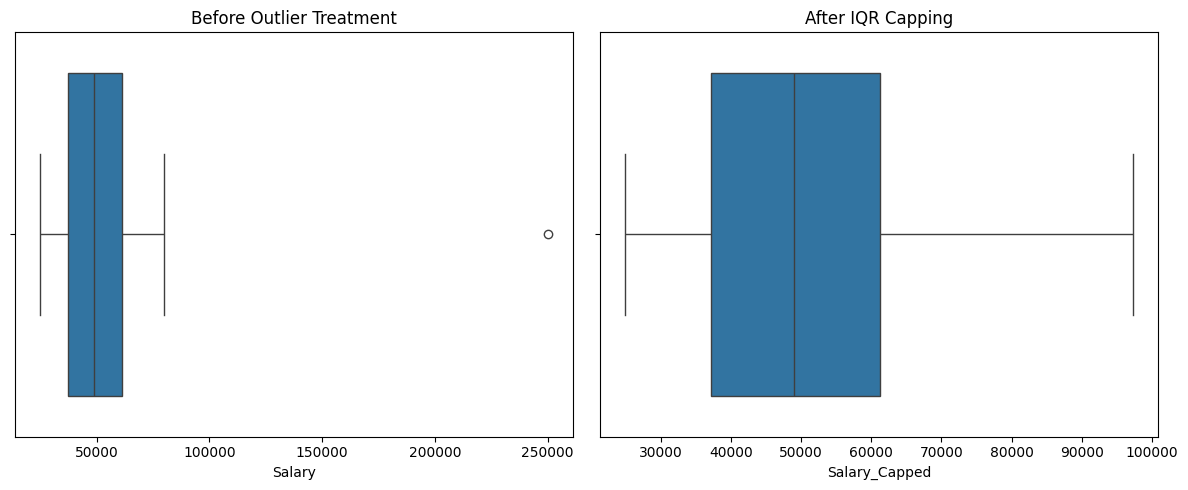


Original Number of Records: 20
Records after IQR Removal: 19
Records after Z-Score Removal: 19
Number of IQR Outliers: 1
Number of Z-Score Outliers: 1


In [1]:

# Outlier Detection and Treatment using IQR and Z-Score

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Create a sample dataset
data = {
    'Salary': [25000, 28000, 30000, 32000, 35000,
               38000, 40000, 42000, 45000, 48000,
               50000, 52000, 55000, 58000, 60000,
               65000, 70000, 75000, 80000, 250000]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

# 2. Visualize original data
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['Salary'])
plt.title("Original Salary Data")
plt.show()

# 3. Detect outliers using IQR method

Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("\nIQR Method")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# Identify IQR outliers
iqr_outliers = df[
    (df['Salary'] < lower_bound) |
    (df['Salary'] > upper_bound)
]

print("\nOutliers using IQR:")
print(iqr_outliers)

# 4. Treat outliers using IQR - Capping

df['Salary_Capped'] = df['Salary'].clip(
    lower=lower_bound,
    upper=upper_bound
)

print("\nDataset after IQR Capping:")
print(df[['Salary', 'Salary_Capped']])

# 5. Remove outliers using IQR

df_iqr_clean = df[
    (df['Salary'] >= lower_bound) &
    (df['Salary'] <= upper_bound)
]

print("\nDataset after removing IQR outliers:")
print(df_iqr_clean[['Salary']])

# 6. Detect outliers using Z-Score

df['Z_Score'] = np.abs(stats.zscore(df['Salary']))

z_outliers = df[df['Z_Score'] > 3]

print("\nZ-Score values:")
print(df[['Salary', 'Z_Score']])

print("\nOutliers using Z-Score:")
print(z_outliers[['Salary', 'Z_Score']])

# 7. Remove outliers using Z-Score

df_z_clean = df[df['Z_Score'] <= 3]

print("\nDataset after removing Z-Score outliers:")
print(df_z_clean[['Salary']])

# 8. Visualize before and after treatment

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x=df['Salary'])
plt.title("Before Outlier Treatment")

plt.subplot(1, 2, 2)
sns.boxplot(x=df['Salary_Capped'])
plt.title("After IQR Capping")

plt.tight_layout()
plt.show()

# 9. Display final results

print("\nOriginal Number of Records:", len(df))
print("Records after IQR Removal:", len(df_iqr_clean))
print("Records after Z-Score Removal:", len(df_z_clean))
print("Number of IQR Outliers:", len(iqr_outliers))
print("Number of Z-Score Outliers:", len(z_outliers))
